In [3]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt

# Import dataset generator
from sklearn.datasets import make_circles

# Import preprocessing and clustering algorithms
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN

# Import evaluation metrics
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [4]:
# Generate circular dataset
X, y_true = make_circles(
    n_samples=600,
    noise=0.05,
    factor=0.45,
    random_state=42
)

# Display dataset dimensions
print("Dataset Shape:", X.shape)

Dataset Shape: (600, 2)


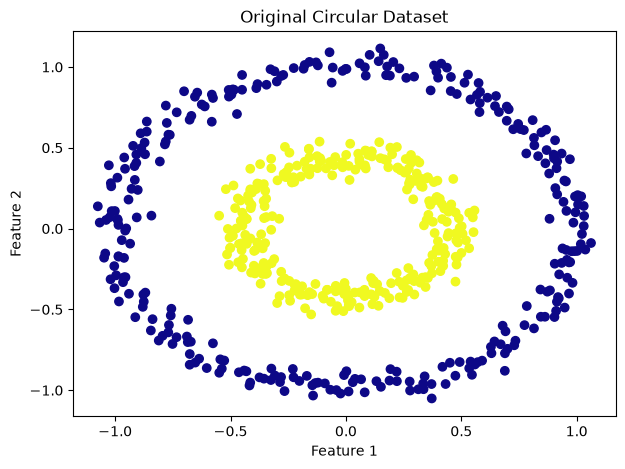

In [5]:
# Create figure
plt.figure(figsize=(7, 5))

# Plot original data points
plt.scatter(X[:, 0], X[:, 1], c=y_true, cmap="plasma")

# Add title and labels
plt.title("Original Circular Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

# Display graph
plt.show()

In [6]:
# Create scaler object
scaler = StandardScaler()

# Transform features into standardized values
X_scaled = scaler.fit_transform(X)

In [7]:
# Initialize K-Means algorithm
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=15
)

# Train model and assign cluster labels
kmeans_labels = kmeans.fit_predict(X_scaled)

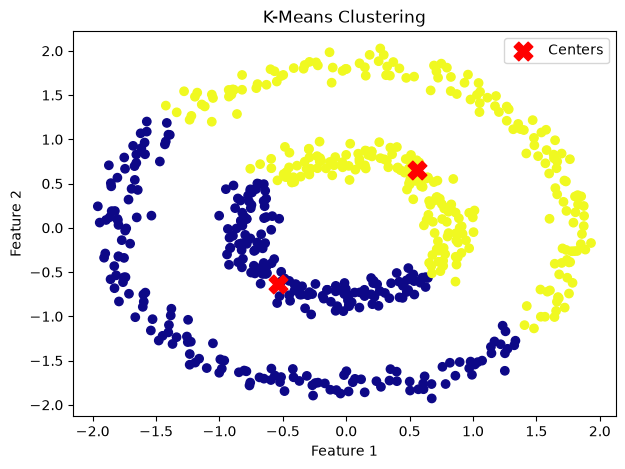

In [8]:
# Create figure
plt.figure(figsize=(7, 5))

# Plot clustered points
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="plasma"
)

# Plot cluster centers
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color="red",
    marker="X",
    s=180,
    label="Centers"
)

# Add title and labels
plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()

plt.show()

In [9]:
# Initialize DBSCAN algorithm
dbscan = DBSCAN(
    eps=0.18,
    min_samples=6
)

# Fit model and predict cluster labels
dbscan_labels = dbscan.fit_predict(X_scaled)

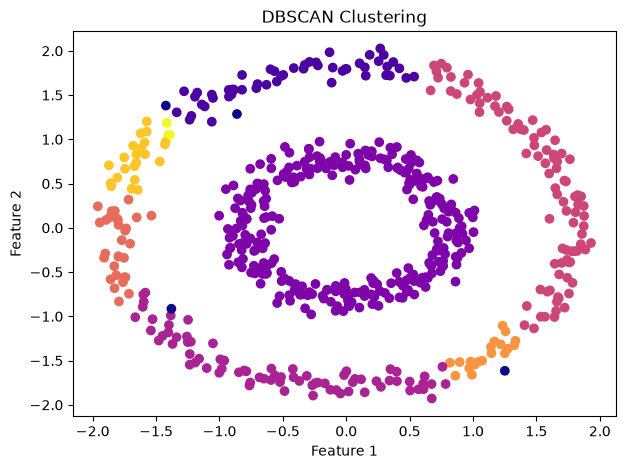

In [10]:
# Create figure
plt.figure(figsize=(7, 5))

# Plot DBSCAN clusters
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=dbscan_labels,
    cmap="plasma"
)

# Add title and labels
plt.title("DBSCAN Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [13]:
# Initialize DBSCAN with adjusted parameters
dbscan = DBSCAN(
    eps=0.25,
    min_samples=5
)

# Fit model and predict cluster labels
dbscan_labels = dbscan.fit_predict(X_scaled)

# Display unique cluster labels
print("Cluster Labels:", np.unique(dbscan_labels))

Cluster Labels: [0 1]


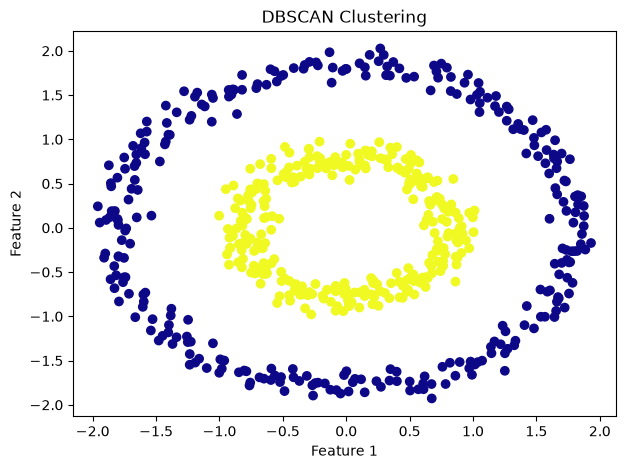

In [14]:
# Create figure
plt.figure(figsize=(7, 5))

# Plot DBSCAN clusters
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=dbscan_labels,
    cmap="plasma"
)

# Add title and labels
plt.title("DBSCAN Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.show()

In [15]:
# Calculate K-Means Silhouette Score
kmeans_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels
)

# Calculate K-Means Adjusted Rand Index
kmeans_ari = adjusted_rand_score(
    y_true,
    kmeans_labels
)

# Remove noise points from DBSCAN
mask = dbscan_labels != -1

# Get valid cluster labels
valid_labels = dbscan_labels[mask]

# Calculate DBSCAN Silhouette Score
if len(np.unique(valid_labels)) > 1:
    dbscan_silhouette = silhouette_score(
        X_scaled[mask],
        valid_labels
    )
else:
    dbscan_silhouette = np.nan

# Calculate DBSCAN Adjusted Rand Index
dbscan_ari = adjusted_rand_score(
    y_true,
    dbscan_labels
)

In [16]:
# Count clusters excluding noise (-1)
n_clusters = len(set(dbscan_labels)) - (
    1 if -1 in dbscan_labels else 0
)

# Count noise points
n_noise = np.sum(dbscan_labels == -1)

# Display DBSCAN results
print("\nDBSCAN RESULTS")

print("Number of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)
print("Silhouette Score:", dbscan_silhouette)
print("Adjusted Rand Index:", dbscan_ari)


DBSCAN RESULTS
Number of Clusters: 2
Number of Noise Points: 0
Silhouette Score: 0.13581507711409363
Adjusted Rand Index: 1.0


In [17]:
# Display clustering comparison
print("\nCLUSTERING COMPARISON")

# K-Means results
print("\nK-Means:")
print("Silhouette Score:", kmeans_silhouette)
print("Adjusted Rand Index:", kmeans_ari)

# DBSCAN results
print("\nDBSCAN:")
print("Silhouette Score:", dbscan_silhouette)
print("Adjusted Rand Index:", dbscan_ari)


CLUSTERING COMPARISON

K-Means:
Silhouette Score: 0.342291803874302
Adjusted Rand Index: -0.0016270520517674867

DBSCAN:
Silhouette Score: 0.13581507711409363
Adjusted Rand Index: 1.0


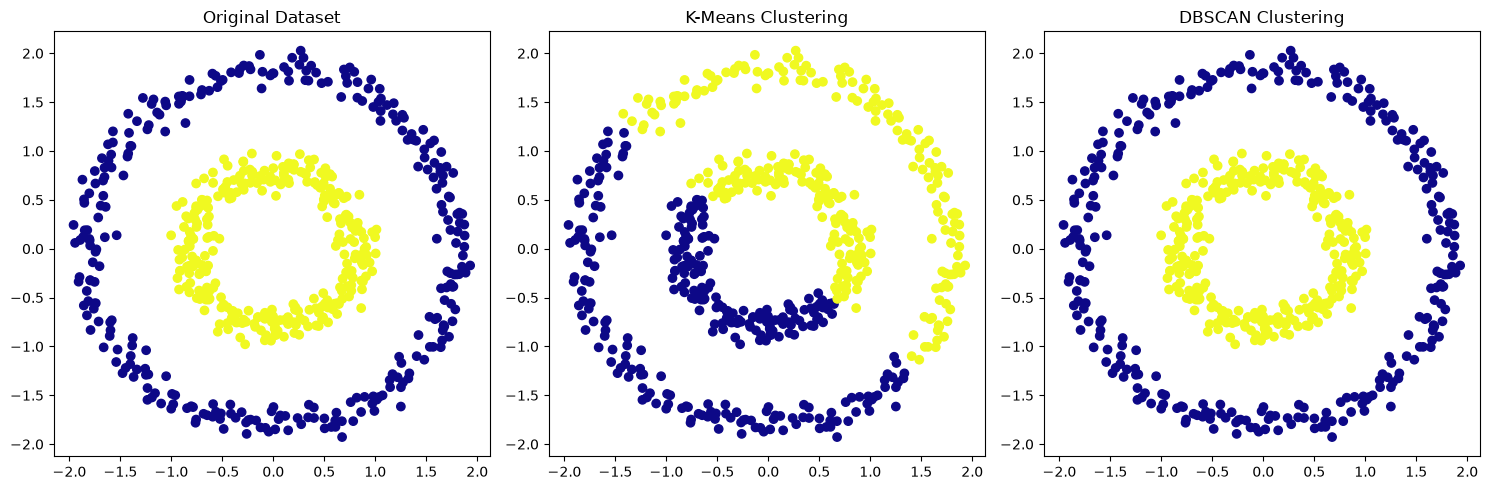

In [18]:
# Create three subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot original dataset
axes[0].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y_true,
    cmap="plasma"
)
axes[0].set_title("Original Dataset")

# Plot K-Means results
axes[1].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="plasma"
)
axes[1].set_title("K-Means Clustering")

# Plot final DBSCAN results
axes[2].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=dbscan_labels,
    cmap="plasma"
)
axes[2].set_title("DBSCAN Clustering")

# Adjust spacing
plt.tight_layout()

# Display all plots
plt.show()